# Comprehensive Time-Series Forecasting Pipeline

This notebook synthesizes coursework on time-series analysis, covering decomposition, detrending (Linear Algebra), smoothing, stationarity, ACF/PACF analysis, and culminates in a walk-forward backtest comparing a Seasonal Naive baseline against SARIMAX.

## 1. Setup & Data Loading (Labs 1-2)
Loading the Mauna Loa CO2 dataset.

Dataset: 526 monthly observations


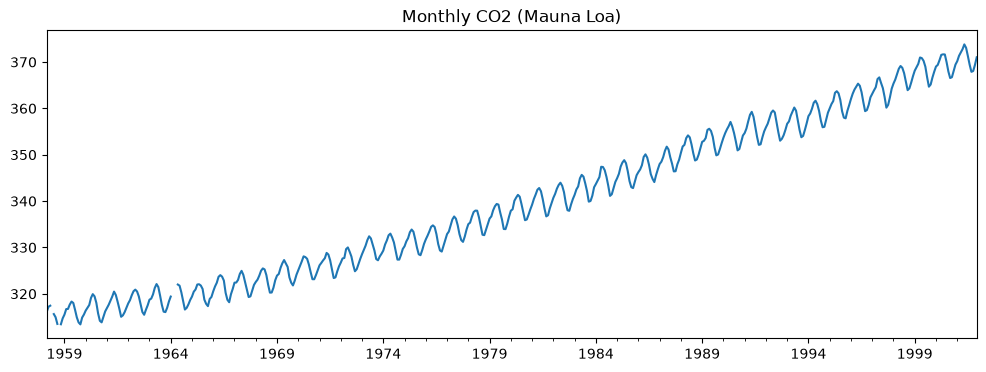

In [1]:
import sys, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
sys.path.append(os.path.abspath('..'))
from data.data_loader import get_co2_monthly

series = get_co2_monthly()
print(f'Dataset: {len(series)} monthly observations')
series.plot(figsize=(12, 4), title='Monthly CO2 (Mauna Loa)')
plt.show()

## 2. Classical Decomposition (Lab 3)
Decomposing the series into Trend, Seasonality, and Residuals.

In [2]:
decomp = seasonal_decompose(series, model='additive')
fig = decomp.plot()
fig.set_size_inches(10, 8)
plt.show()

# Variance Analysis
print(f"Variance of Trend: {np.var(decomp.trend.dropna()):.4f}")
print(f"Variance of Seasonality: {np.var(decomp.seasonal.dropna()):.4f}")

ValueError: This function does not handle missing values

## 3. Detrending via Linear Algebra (Lab 4)
Fitting a linear trend using the Normal Equation (OLS) via `np.linalg.lstsq`.

In [ ]:
# Matrix approach: y = X * beta + error
X = np.arange(len(series)).reshape(-1, 1)
X = np.hstack([np.ones((len(series), 1)), X]) # Add intercept
y = series.values

# Solve OLS
beta = np.linalg.lstsq(X, y, rcond=None)[0]
trend = X @ beta
detrended = y - trend

plt.figure(figsize=(12, 4))
plt.plot(series.index, y, label='Original')
plt.plot(series.index, trend, label='Fitted Trend', color='red')
plt.legend()
plt.show()

## 4. Smoothing & Moving Averages (Labs 5-6)
Applying Simple Moving Average (SMA) and Exponential Smoothing.

In [ ]:
sma_12 = series.rolling(window=12).mean()
sma_24 = series.rolling(window=24).mean()

plt.figure(figsize=(12, 4))
plt.plot(series, label='Original', alpha=0.5)
plt.plot(sma_12, label='12-Month SMA')
plt.plot(sma_24, label='24-Month SMA')
plt.legend()
plt.show()

## 5. Stationarity & ACF/PACF Analysis (Labs 7-8)
Augmented Dickey-Fuller test and Autocorrelation plots to determine AR/MA orders.

In [ ]:
def check_stationarity(ts):
    result = adfuller(ts.dropna(), autolag='AIC')
    print(f"ADF Statistic: {result[0]:.4f} (p-value: {result[1]:.4f})")

print("Raw Series:")
check_stationarity(series)

# First Differencing to achieve stationarity
diff_series = series.diff().dropna()
print("\nDifferenced Series:")
check_stationarity(diff_series)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diff_series, ax=axes[0])
plot_pacf(diff_series, ax=axes[1])
plt.show()

## 6. Walk-Forward Backtesting: SARIMAX vs Baseline (Labs 9-11)
Evaluating the model using expanding-window backtesting (MAE, RMSE, MAPE).

In [ ]:
from src.models import seasonal_naive_forecast, sarimax_forecast
from src.backtest import walk_forward_validate
from src.evaluate import save_results

horizon, folds = 12, 4

# Run Baseline
res_naive = walk_forward_validate(series, seasonal_naive_forecast, horizon=horizon, n_folds=folds, season_length=12)
# Run SARIMAX
res_sarima = walk_forward_validate(series, sarimax_forecast, horizon=horizon, n_folds=folds)

df_metrics = save_results({'Seasonal Naive': res_naive, 'SARIMAX': res_sarima})

improvement = ((res_naive['MAPE'] - res_sarima['MAPE']) / res_naive['MAPE']) * 100
print(f"\nSARIMAX reduced MAPE by {improvement:.1f}% compared to baseline.")